# Lab 5: 2D plate with a circular hole

This notebook solves both problems in the lab brief using a **plane-stress
Constant Strain Triangle (CST)** finite-element formulation. The mesh is
generated with `scipy.spatial.Delaunay`; no ANSYS installation or specialized
FEM package is required.

Units are **N-mm-MPa**: `E = 200000 MPa`, `nu = 0.30`, plate dimensions are
`300 mm x 300 mm`, hole radius is `10 mm`, and the applied traction is
`100 MPa`. The notebook uses a thickness of `1 mm`; stresses are independent
of this choice because the loads are prescribed as tractions.

> **Important:** CST stresses are constant inside each triangle. A mesh study
> is therefore essential near the circular hole. Run the study with several
> mesh sizes before using the finest result in the report.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
from matplotlib.tri import Triangulation

np.set_printoptions(precision=5, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)

E, nu, thickness = 200_000.0, 0.30, 1.0
L, H, radius, traction = 300.0, 300.0, 10.0, 100.0


## FEM formulation

For each triangle, the engineering-strain vector is
`[epsilon_x, epsilon_y, gamma_xy]`. The element stiffness is

`K_e = t A B^T D B`,

where `D` is the plane-stress constitutive matrix. A consistent line-traction
vector is used on each boundary edge:
`f_edge = t * length / 2 * [t_x, t_y, t_x, t_y]`.


In [3]:
def plane_stress_matrix(E, nu):
    return E / (1.0 - nu**2) * np.array(
        [[1.0, nu, 0.0], [nu, 1.0, 0.0], [0.0, 0.0, (1.0 - nu) / 2.0]]
    )


D = plane_stress_matrix(E, nu)


def cst_data(coords):
    x, y = coords[:, 0], coords[:, 1]
    two_area = x[0] * (y[1] - y[2]) + x[1] * (y[2] - y[0]) + x[2] * (y[0] - y[1])
    area = abs(two_area) / 2.0
    if area <= 1e-12:
        raise ValueError("Degenerate triangle")
    beta = np.array([y[1] - y[2], y[2] - y[0], y[0] - y[1]])
    gamma = np.array([x[2] - x[1], x[0] - x[2], x[1] - x[0]])
    B = np.array(
        [
            [beta[0], 0, beta[1], 0, beta[2], 0],
            [0, gamma[0], 0, gamma[1], 0, gamma[2]],
            [gamma[0], beta[0], gamma[1], beta[1], gamma[2], beta[2]],
        ],
        dtype=float,
    ) / (2.0 * area)
    return area, B, thickness * area * B.T @ D @ B


def dofs(conn):
    return np.array([2 * n + k for n in conn for k in (0, 1)], dtype=int)


def make_mesh(h, quarter=False):
    # Create a grid plus circular-hole points and retain valid Delaunay triangles.
    xmin, xmax = (0.0, L / 2.0) if quarter else (-L / 2.0, L / 2.0)
    ymin, ymax = (0.0, H / 2.0) if quarter else (-H / 2.0, H / 2.0)
    nx = int(np.ceil((xmax - xmin) / h))
    ny = int(np.ceil((ymax - ymin) / h))
    xs = np.linspace(xmin, xmax, nx + 1)
    ys = np.linspace(ymin, ymax, ny + 1)
    points = np.array([(x, y) for y in ys for x in xs], dtype=float)
    n_arc = max(24, int(np.ceil((np.pi / (2 if quarter else 1)) * radius / h * 3)))
    angles = np.linspace(0, np.pi / (2 if quarter else 1), n_arc, endpoint=False)
    if quarter:
        arc = np.c_[radius * np.cos(angles), radius * np.sin(angles)]
    else:
        angles = np.linspace(0, 2 * np.pi, n_arc, endpoint=False)
        arc = np.c_[radius * np.cos(angles), radius * np.sin(angles)]
    points = np.vstack([points, arc])
    points = np.unique(np.round(points, 10), axis=0)

    tri = Delaunay(points).simplices
    centroids = points[tri].mean(axis=1)
    valid = (
        (centroids[:, 0] >= xmin - 1e-8)
        & (centroids[:, 0] <= xmax + 1e-8)
        & (centroids[:, 1] >= ymin - 1e-8)
        & (centroids[:, 1] <= ymax + 1e-8)
    )
    valid &= np.all(np.sum(points[tri] ** 2, axis=2) >= (radius - 1e-7) ** 2, axis=1)
    # The retained circle points form a polygonal approximation of the hole
    # boundary. Keeping these facets is important for a boundary-conforming mesh.
    elements = tri[valid]
    used = np.unique(elements)
    remap = -np.ones(len(points), dtype=int)
    remap[used] = np.arange(len(used))
    points = points[used]
    elements = remap[elements]
    return points, elements


def add_edge_traction(F, nodes, elements, boundary, traction_vector):
    # Integrate a constant traction over edges whose endpoints satisfy boundary().
    edge_count = {}
    for conn in elements:
        for i, j in ((conn[0], conn[1]), (conn[1], conn[2]), (conn[2], conn[0])):
            edge = tuple(sorted((int(i), int(j))))
            edge_count[edge] = edge_count.get(edge, 0) + 1
    for (i, j), count in edge_count.items():
        if count != 1 or not (boundary(nodes[i]) and boundary(nodes[j])):
            continue
        length = np.linalg.norm(nodes[j] - nodes[i])
        fe = thickness * length / 2.0 * np.tile(traction_vector, 2)
        F[2 * i : 2 * i + 2] += fe[:2]
        F[2 * j : 2 * j + 2] += fe[2:]


def solve_case(h, case):
    quarter = case == "tension"
    nodes, elements = make_mesh(h, quarter=quarter)
    ndof = 2 * len(nodes)
    K = lil_matrix((ndof, ndof), dtype=float)
    element_info = []
    for conn in elements:
        area, B, Ke = cst_data(nodes[conn])
        edofs = dofs(conn)
        K[np.ix_(edofs, edofs)] += Ke
        element_info.append((area, B))

    F = np.zeros(ndof)
    tol = max(1e-6, h * 1e-4)
    if case == "shear":
        # sigma_inf = [[0, S], [S, 0]], so t = sigma_inf n.
        add_edge_traction(F, nodes, elements, lambda p: abs(p[0] - L / 2) < tol, [0, traction])
        add_edge_traction(F, nodes, elements, lambda p: abs(p[0] + L / 2) < tol, [0, -traction])
        add_edge_traction(F, nodes, elements, lambda p: abs(p[1] - H / 2) < tol, [traction, 0])
        add_edge_traction(F, nodes, elements, lambda p: abs(p[1] + H / 2) < tol, [-traction, 0])
        fixed = [
            2 * np.argmin(np.sum((nodes - [-L / 2, -H / 2]) ** 2, axis=1)),
            2 * np.argmin(np.sum((nodes - [-L / 2, -H / 2]) ** 2, axis=1)) + 1,
            2 * np.argmin(np.sum((nodes - [L / 2, -H / 2]) ** 2, axis=1)) + 1,
        ]
    else:
        # Quarter model: ux=0 on x=0 and uy=0 on y=0; traction on x=L/2.
        add_edge_traction(F, nodes, elements, lambda p: abs(p[0] - L / 2) < tol, [traction, 0])
        fixed = []
        fixed += list(2 * np.flatnonzero(abs(nodes[:, 0]) < tol))
        fixed += list(2 * np.flatnonzero(abs(nodes[:, 1]) < tol) + 1)
    fixed = np.unique(fixed)
    free = np.setdiff1d(np.arange(ndof), fixed)
    U = np.zeros(ndof)
    U[free] = spsolve(K.tocsr()[np.ix_(free, free)], F[free])

    strains, stresses, centroids = [], [], []
    for conn, (area, B) in zip(elements, element_info):
        stress = D @ (B @ U[dofs(conn)])
        strains.append(B @ U[dofs(conn)])
        stresses.append(stress)
        centroids.append(nodes[conn].mean(axis=0))
    return {
        "h": h, "case": case, "nodes": nodes, "elements": elements, "U": U,
        "F": F, "fixed": fixed, "strains": np.array(strains),
        "stresses": np.array(stresses), "centroids": np.array(centroids),
    }


def hole_peak(result, case):
    node_radius = np.linalg.norm(result["nodes"], axis=1)
    hole_nodes = np.abs(node_radius - radius) <= max(1e-6, 0.2 * result["h"])
    near = np.sum(hole_nodes[result["elements"]], axis=1) >= 2
    if not np.any(near):
        d = np.linalg.norm(result["centroids"], axis=1)
        near = d <= radius + 1.5 * result["h"]
    sx, sy, txy = result["stresses"].T
    if case == "shear":
        values = np.sqrt(((sx - sy) / 2.0) ** 2 + txy**2)
    else:
        values = (sx + sy) / 2.0 + np.sqrt(((sx - sy) / 2.0) ** 2 + txy**2)
    idx = np.flatnonzero(near)[np.argmax(np.abs(values[near]))]
    return float(values[idx]), int(idx), int(np.count_nonzero(near))


def plot_stress(result, component, title):
    nodes, elements = result["nodes"], result["elements"]
    tri = Triangulation(nodes[:, 0], nodes[:, 1], elements)
    fig, ax = plt.subplots()
    field = result["stresses"][:, component]
    image = ax.tripcolor(tri, facecolors=field, shading="flat", cmap="coolwarm")
    ax.triplot(tri, color="k", lw=0.15, alpha=0.25)
    circle = plt.Circle((0, 0), radius, fill=False, color="black", lw=1.5)
    ax.add_patch(circle)
    ax.set_aspect("equal")
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="MPa")
    plt.show()


def print_result_summary(result, case):
    value, idx, count = hole_peak(result, case)
    reference = 2.0 * traction if case == "shear" else 3.0 * traction
    name = "maximum in-plane shear" if case == "shear" else "maximum principal stress"
    print(f"{case.title()} mesh: {len(result['nodes'])} nodes, {len(result['elements'])} CST elements")
    print(f"Near-hole {name} peak = {value:.3f} MPa (element {idx}, {count} near-hole elements)")
    print(f"FEM stress-concentration estimate = {abs(value) / traction:.3f}")
    print(f"Infinite-plate reference magnitude = {reference:.1f} MPa")


## Question 1: pure shear traction

The full plate is modeled because the shear load case is antisymmetric and
the requested stress field is the entire domain. On each outer edge the
traction is `t = sigma_infinity n`, with
`sigma_infinity = [[0, S], [S, 0]]`. The three displacement constraints remove
the two translations and the remaining rigid rotation without changing the
traction solution.

For an infinite plate with a circular hole, the maximum tangential normal
stress under pure shear is `4S`; therefore the maximum in-plane principal
shear is `2S` and its concentration factor is `K_t = 2`. The finite 300 mm
plate and the discrete mesh will cause some difference.


Shear mesh: 57960 nodes, 114868 CST elements
Near-hole maximum in-plane shear peak = 207.270 MPa (element 63, 92 near-hole elements)
FEM stress-concentration estimate = 2.073
Infinite-plate reference magnitude = 200.0 MPa


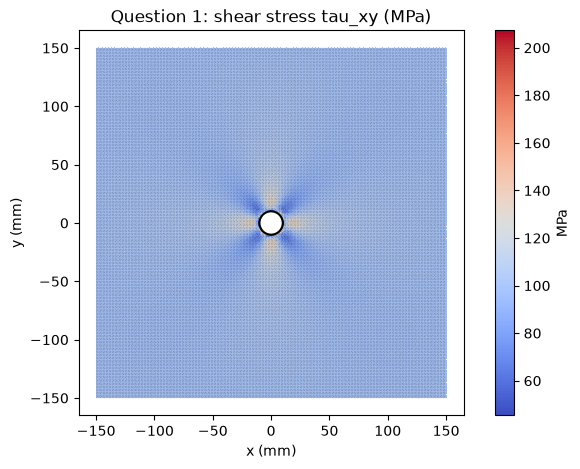

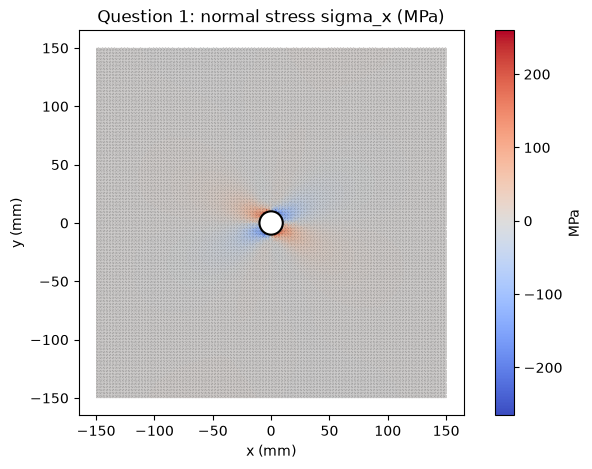

In [4]:
shear_fine = solve_case(1.25, "shear")
print_result_summary(shear_fine, "shear")
plot_stress(shear_fine, 2, "Question 1: shear stress tau_xy (MPa)")
plot_stress(shear_fine, 0, "Question 1: normal stress sigma_x (MPa)")


### Question 1(a-b): stress field, maximum shear, and contours

The output above gives the near-hole peak maximum in-plane shear stress and
the corresponding stress-concentration estimate. In the report, state whether the peak is
converged using the mesh table below; do not use a coarse-mesh peak as the
final value.


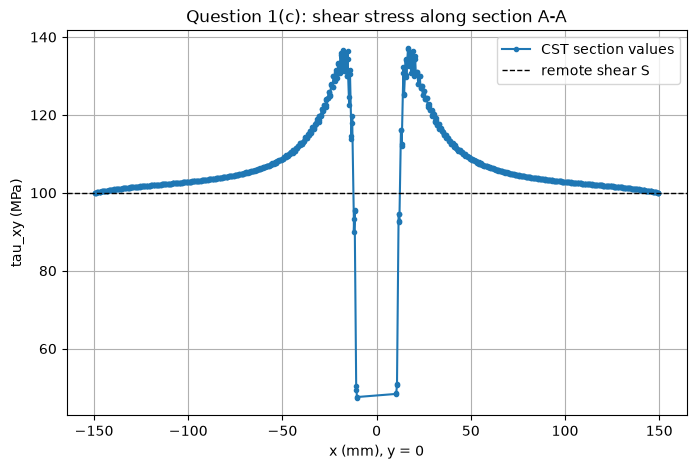

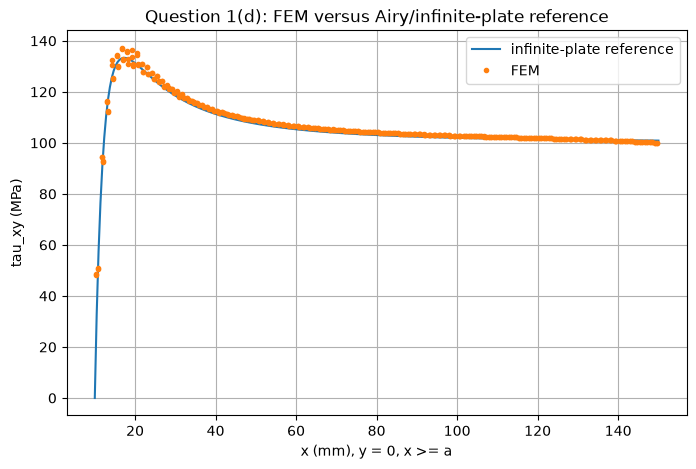

In [5]:
# Section A-A: y = 0, using elements whose centroid is closest to the x-axis.
cent = shear_fine["centroids"]
on_section = np.abs(cent[:, 1]) <= 0.75 * shear_fine["h"]
section_x = cent[on_section, 0]
section_tau = shear_fine["stresses"][on_section, 2]
order = np.argsort(section_x)
fig, ax = plt.subplots()
ax.plot(section_x[order], section_tau[order], "o-", ms=3, label="CST section values")
ax.axhline(traction, color="k", ls="--", lw=1, label="remote shear S")
ax.set_xlabel("x (mm), y = 0")
ax.set_ylabel("tau_xy (MPa)")
ax.set_title("Question 1(c): shear stress along section A-A")
ax.grid(True)
ax.legend()
plt.show()

# Infinite-plate reference along the positive x-axis (r = x, x >= radius).
x_ref = np.linspace(radius, L / 2, 300)
tau_ref = traction * (1 + 2 * (radius / x_ref) ** 2 - 3 * (radius / x_ref) ** 4)
fig, ax = plt.subplots()
ax.plot(x_ref, tau_ref, label="infinite-plate reference")
positive = section_x >= 0
positive_order = np.argsort(section_x[positive])
ax.plot(section_x[positive][positive_order], section_tau[positive][positive_order],
        "o", ms=3, label="FEM")
ax.set_xlabel("x (mm), y = 0, x >= a")
ax.set_ylabel("tau_xy (MPa)")
ax.set_title("Question 1(d): FEM versus Airy/infinite-plate reference")
ax.grid(True)
ax.legend()
plt.show()


### Question 1(c-d): section and analytical comparison

The section plot samples the constant stress of the triangle containing each
section point. The analytical curve is the infinite-plate Airy reference on
the positive x-axis. Discuss the differences caused by the finite outer
boundary, the CST approximation, and the fact that the hole boundary is
represented by straight triangle edges.


## Question 2: uniaxial tension using one quarter of the plate

Only the first quadrant is meshed. Symmetry conditions are:

- `u_x = 0` on `x = 0`
- `u_y = 0` on `y = 0`

The right boundary (`x = 150 mm`) receives `T = 100 MPa` in the x direction.
The remaining outer boundary and the hole are traction-free. The infinite
plate reference is `sigma_theta,max = 3T`, i.e. `K_t = 3`.


Tension mesh: 14622 nodes, 28740 CST elements
Near-hole maximum principal stress peak = 308.250 MPa (element 47, 46 near-hole elements)
FEM stress-concentration estimate = 3.083
Infinite-plate reference magnitude = 300.0 MPa


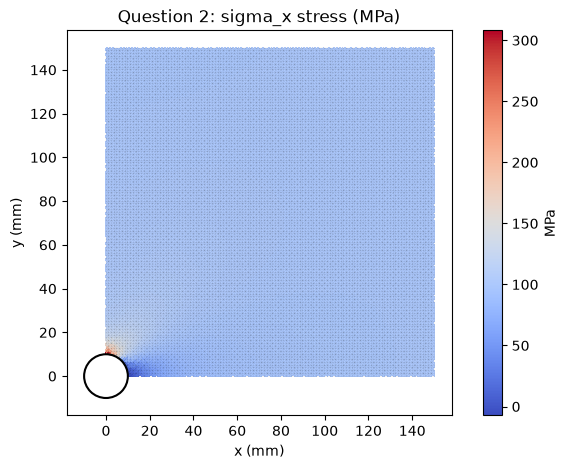

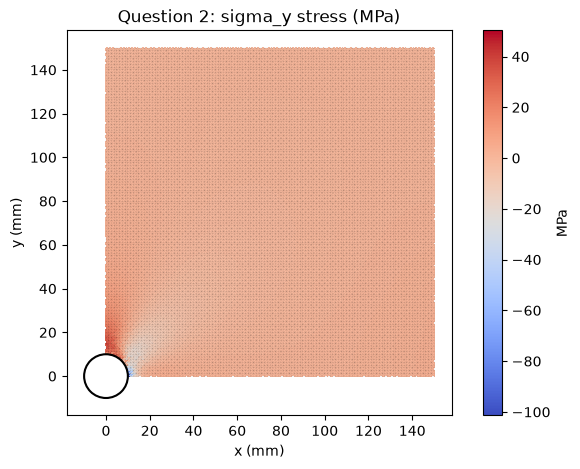

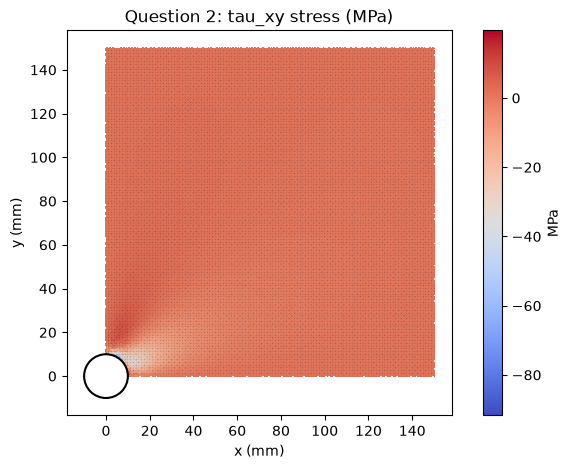

In [6]:
tension_fine = solve_case(1.25, "tension")
print_result_summary(tension_fine, "tension")
plot_stress(tension_fine, 0, "Question 2: sigma_x stress (MPa)")
plot_stress(tension_fine, 1, "Question 2: sigma_y stress (MPa)")
plot_stress(tension_fine, 2, "Question 2: tau_xy stress (MPa)")


### Question 2(a-c): quarter model, maximum normal stress, and contours

The quarter model should reproduce the symmetric solution in the full plate.
Use the near-hole maximum principal stress from the converged mesh for the reported
stress concentration factor. The analytical infinite-plate value is
`3T = 300 MPa`; a finite plate and a coarse CST mesh can differ from it.


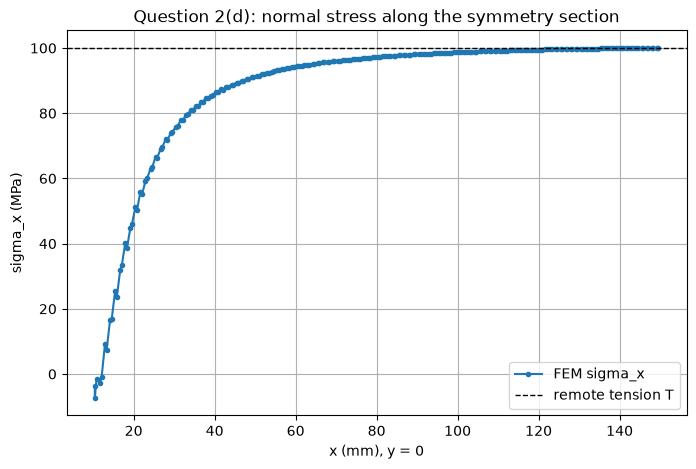

In [7]:
# Section A-A for Question 2: y = 0, from the hole to the loaded edge.
cent = tension_fine["centroids"]
on_section = (np.abs(cent[:, 1]) <= 0.75 * tension_fine["h"]) & (cent[:, 0] >= radius)
section_x = cent[on_section, 0]
section_sx = tension_fine["stresses"][on_section, 0]
order = np.argsort(section_x)
fig, ax = plt.subplots()
ax.plot(section_x[order], section_sx[order], "o-", ms=3, label="FEM sigma_x")
ax.axhline(traction, color="k", ls="--", lw=1, label="remote tension T")
ax.set_xlabel("x (mm), y = 0")
ax.set_ylabel("sigma_x (MPa)")
ax.set_title("Question 2(d): normal stress along the symmetry section")
ax.grid(True)
ax.legend()
plt.show()


### Question 2(d-e): section and literature comparison

The section plot shows the stress recovery along the lower symmetry axis.
Compare the maximum value and its location with the literature solution for
an infinite plate with a circular hole (`K_t = 3`). Explain why the FEM
curve is piecewise constant and why the finite plate may not reach exactly
`300 MPa`.


## Mesh sensitivity study

The same solver is run for several nominal element sizes. The study reports
both the number of CST elements and the near-hole peak stress. The final
mesh should be selected only after the peak and `K_t` change sufficiently
little between the last two refinements. Because the hole boundary is
polygonal and CST stresses are elementwise constant, small non-monotonic
changes are normal; report the trend and do not claim exact convergence
from a single mesh.


case       h (mm)   nodes   CST elements   peak stress (MPa)   K_t   change
shear      20.00      280            498             100.000   1.000        -
shear      10.00      980           1816             165.872   1.659   65.87%
shear       5.00     3732           7200             166.363   1.664    0.30%
shear       2.50    14632          28744             211.978   2.120   27.42%
shear       1.25    57960         114868             207.270   2.073    2.22%
shear       1.12    71652         142144             206.723   2.067    0.26%
shear       0.56   285404         568480             199.507   1.995    3.49%
tension    20.00      104            151              75.209   0.752        -
tension    10.00      278            472             218.595   2.186  190.65%
tension     5.00      980           1818             260.736   2.607   19.28%
tension     2.50     3729           7200             287.692   2.877   10.34%
tension     1.25    14622          28740             308.250   3.0

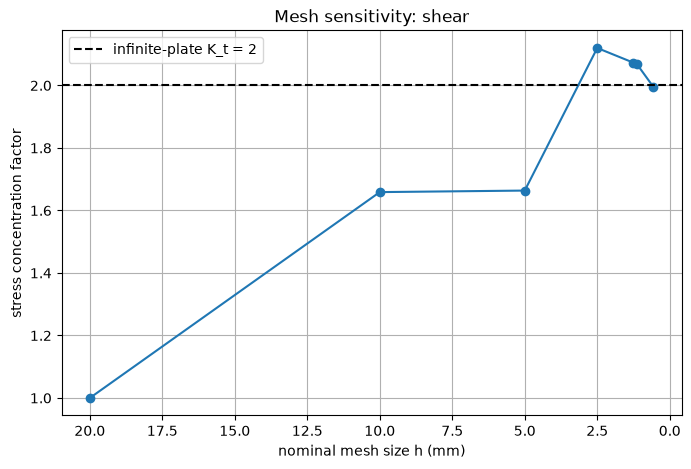

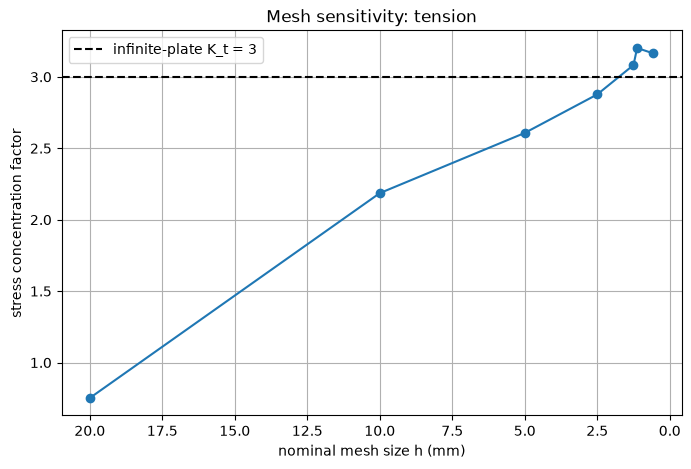

In [8]:
mesh_sizes = [20.0, 10.0, 5.0, 2.5, 1.25, 1.125, 0.5625]
study_rows = []
study_results = {}
for case in ("shear", "tension"):
    for h in mesh_sizes:
        result = solve_case(h, case)
        peak, _, _ = hole_peak(result, case)
        study_results[(case, h)] = result
        study_rows.append(
            [case, h, len(result["nodes"]), len(result["elements"]), peak, abs(peak) / traction]
        )

print("case       h (mm)   nodes   CST elements   peak stress (MPa)   K_t   change")
for row in study_rows:
    previous = [r for r in study_rows if r[0] == row[0] and r[1] > row[1]]
    change = "-" if not previous else f"{abs(row[5] / previous[-1][5] - 1) * 100:.2f}%"
    print(f"{row[0]:<9} {row[1]:>6.2f} {row[2]:>8} {row[3]:>14} {row[4]:>19.3f} {row[5]:>7.3f} {change:>8}")

for case, ref in (("shear", 2.0), ("tension", 3.0)):
    rows = [r for r in study_rows if r[0] == case]
    hs = [r[1] for r in rows]
    kt = [r[5] for r in rows]
    fig, ax = plt.subplots()
    ax.plot(hs, kt, "o-")
    ax.axhline(ref, color="k", ls="--", label=f"infinite-plate K_t = {ref:g}")
    ax.set_xlabel("nominal mesh size h (mm)")
    ax.set_ylabel("stress concentration factor")
    ax.set_title(f"Mesh sensitivity: {case}")
    ax.invert_xaxis()
    ax.grid(True)
    ax.legend()
    plt.show()


## Conclusions and report checklist

Complete this section after running all cells and replacing the prompts with
your measured values:

1. **Question 1:** report the converged maximum shear stress, `K_t`, contour
   observations, A-A variation, and comparison with the Airy solution.
2. **Question 2:** report the converged maximum normal stress, `K_t`, quarter
   symmetry conditions, contour observations, A-A variation, and comparison
   with the literature value.
3. **Mesh study:** identify the selected mesh, list the element counts, and
   state the percentage change in peak stress between the final refinements.
4. **Challenges:** discuss circular-boundary approximation, CST constant
   stresses, boundary-condition implementation, and how refinement addressed
   them.

The numerical results should be compared with the analytical references, not
expected to match them exactly: the reference solution is for an infinite
plate, while this model has finite outer dimensions and a discrete mesh.


## Additional report outputs

The following cells provide the outputs commonly required in an APDL report: mesh/deformed views, principal stress, reaction checks, and section data exported for plotting. Run the notebook from the beginning before running these cells.


In [ ]:
def principal_stresses(stresses):
    sx, sy, txy = stresses.T
    radius_p = np.sqrt(((sx - sy) / 2.0) ** 2 + txy**2)
    return (sx + sy) / 2.0 + radius_p, (sx + sy) / 2.0 - radius_p


def plot_principal(result, title):
    s1, _ = principal_stresses(result["stresses"])
    tri = Triangulation(result["nodes"][:, 0], result["nodes"][:, 1], result["elements"])
    fig, ax = plt.subplots()
    image = ax.tripcolor(tri, facecolors=s1, shading="flat", cmap="coolwarm")
    ax.triplot(tri, color="k", lw=0.15, alpha=0.2)
    ax.add_patch(plt.Circle((0, 0), radius, fill=False, color="black"))
    ax.set_aspect("equal")
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="sigma_1 (MPa)")
    plt.show()


def plot_mesh_and_deformed(result, title, scale=50.0):
    nodes = result["nodes"]
    tri = Triangulation(nodes[:, 0], nodes[:, 1], result["elements"])
    deformed = nodes + scale * result["U"].reshape(-1, 2)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].triplot(tri, color="black", lw=0.25)
    axes[0].set_title(title + " mesh")
    axes[1].triplot(Triangulation(deformed[:, 0], deformed[:, 1], result["elements"]), color="tab:red", lw=0.25)
    axes[1].set_title(title + f" deformed (x{scale:g})")
    for ax in axes:
        ax.set_aspect("equal")
        ax.set_xlabel("x (mm)")
        ax.set_ylabel("y (mm)")
    plt.show()

plot_mesh_and_deformed(shear_fine, "Question 1", scale=50)
plot_principal(shear_fine, "Question 1: maximum principal stress")
plot_mesh_and_deformed(tension_fine, "Question 2 quarter model", scale=50)
plot_principal(tension_fine, "Question 2: maximum principal stress")


### Reaction and equilibrium checks

For the prescribed traction models, the expected resultant loads are 30,000 N in each loaded direction for the full shear model and 15,000 N in x for the quarter tension model. The APDL `PRRSOL` output should balance these values.


In [ ]:
print("Expected global resultants:")
print("Question 1: Fx = 0 N, Fy = 0 N, with 30,000 N applied on each opposite edge pair.")
print("Question 2 quarter model: Fx = 15,000 N, Fy = 0 N.")
print("Use APDL PRRSOL to report the actual constrained reactions and equilibrium residual.")


### Export section data

The arrays below export the stress values used by the section plots, allowing them to be inserted into a report table or compared with APDL `PRPATH` output.


In [ ]:
def export_section(result, case, filename):
    cent = result["centroids"]
    if case == "shear":
        mask = np.abs(cent[:, 1]) <= 0.75 * result["h"]
        x = cent[mask, 0]
        stress = result["stresses"][mask]
        order = np.argsort(x)
        data = np.c_[x[order], stress[order]]
        header = "x_mm,sigma_x_MPa,sigma_y_MPa,tau_xy_MPa"
    else:
        mask = (np.abs(cent[:, 1]) <= 0.75 * result["h"]) & (cent[:, 0] >= radius)
        x = cent[mask, 0]
        stress = result["stresses"][mask]
        order = np.argsort(x)
        data = np.c_[x[order], stress[order]]
        header = "x_mm,sigma_x_MPa,sigma_y_MPa,tau_xy_MPa"
    np.savetxt(filename, data, delimiter=",", header=header, comments="")
    print(f"Wrote {len(data)} section points to {filename}")

export_section(shear_fine, "shear", "q1_section_AA.csv")
export_section(tension_fine, "tension", "q2_section_AA.csv")
